# Lab 4 – Partea 3: antrenarea și regularizarea

Pornim de la cea mai bună arhitectură din Partea 2 și testăm learning rate, L1, L2, batch normalization, dropout și early stopping.
La final antrenăm modelul cel mai bun și comparăm toate experimentele echipei.

In [1]:
import sys, json
from pathlib import Path
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), None)
assert ROOT is not None, "Ruleaza notebook-ul din interiorul folderului proiectului."
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import lab4_common

DEVICE = lab4_common.get_device()
print("Device:", DEVICE)

Device: cpu


In [3]:
base = json.loads((lab4_common.OUT_DIR / "part2_selected_architecture.json").read_text(encoding="utf-8"))
BASE_CFG = base["config"]
print("Pornesc de la:", base["experiment"], "| macro-F1 =", round(base["val_f1_mean"], 3))

Pornesc de la: p2_filters64 | macro-F1 = 0.767


Pornim de la p2_filters64 (macro-F1 0.767). Pe curbele lui se vede overfitting: pe antrenare ajunge la F1 0.88,
pe validare rămâne la 0.75. De aceea încercăm metode de regularizare.

## Grid-ul de antrenare

In [4]:
BASE = {k: v for k, v in BASE_CFG.items() if k != "name"}

GRID = {
    "p3_lr3e-4":    dict(lr=3e-4),
    "p3_l2_1e-4":   dict(weight_decay=1e-4),
    "p3_l1_1e-5":   dict(l1=1e-5),
    "p3_batchnorm": dict(batch_norm=True),
    "p3_dropout03": dict(dropout=0.3),
    "p3_dropout05": dict(dropout=0.5),
    "p3_long_es":   dict(epochs=60, patience=10),
}

for name, changes in GRID.items():
    print(f"\n=== {name}: {changes} ===")
    cfg = lab4_common.make_config(**{**BASE, **changes, "name": name})
    lab4_common.run_experiment(cfg, device=DEVICE, verbose=False)


=== p3_lr3e-4: {'lr': 0.0003} ===
[p3_lr3e-4] gata: macro-F1 = 0.739 ± 0.005

=== p3_l2_1e-4: {'weight_decay': 0.0001} ===
[p3_l2_1e-4] gata: macro-F1 = 0.763 ± 0.017

=== p3_l1_1e-5: {'l1': 1e-05} ===
[p3_l1_1e-5] gata: macro-F1 = 0.770 ± 0.008

=== p3_batchnorm: {'batch_norm': True} ===
[p3_batchnorm] gata: macro-F1 = 0.781 ± 0.024

=== p3_dropout03: {'dropout': 0.3} ===
[p3_dropout03] gata: macro-F1 = 0.757 ± 0.015

=== p3_dropout05: {'dropout': 0.5} ===
[p3_dropout05] gata: macro-F1 = 0.751 ± 0.016

=== p3_long_es: {'epochs': 60, 'patience': 10} ===
[p3_long_es] gata: macro-F1 = 0.772 ± 0.013


### Rezultatele grid-ului

Modelul de pornire, p2_filters64, are macro-F1 0.767 ± 0.012. Față de el, fiecare experiment a schimbat un singur hiperparametru.

Batch normalization a dat cel mai bun rezultat, 0.781, adică cu 0.014 mai mult decât modelul de pornire.
Antrenarea mai lungă, cu 60 de epoci și patience 10, a ajuns la 0.772, iar regularizarea L1 la 0.770, deci amândouă au ajutat puțin.
Regularizarea L2 a dat 0.763, practic același rezultat ca modelul de pornire.

Celelalte schimbări au scăzut performanța: dropout-ul a dat 0.757 cu probabilitatea 0.3 și 0.751 cu 0.5,
iar learning rate-ul mai mic (0.0003) a dat cel mai slab rezultat, 0.739.

Diferențele mai mici de aproximativ 0.01 sunt în limita variației dintre fold-uri, deci singura îmbunătățire clară
este cea adusă de batch normalization. Explicațiile pentru fiecare rezultat sunt în secțiunea următoare.

,name,val_f1_mean,val_f1_std,train_f1_mean,gap_train_val,best_epoch_mean,train_minutes_total
0,p3_batchnorm,0.781,0.024,0.846,0.065,18.0,89.831
1,p3_long_es,0.772,0.013,0.872,0.101,28.6,46.161
2,p3_l1_1e-5,0.770,0.008,0.835,0.066,26.2,50.827
3,p2_filters64,0.767,0.012,0.851,0.085,25.4,6.008
5,p3_l2_1e-4,0.763,0.017,0.804,0.040,20.2,47.299
6,p3_dropout03,0.757,0.015,0.791,0.034,22.2,50.754
7,p3_dropout05,0.751,0.016,0.768,0.016,21.6,43.362
10,p3_lr3e-4,0.739,0.005,0.758,0.019,26.4,57.124


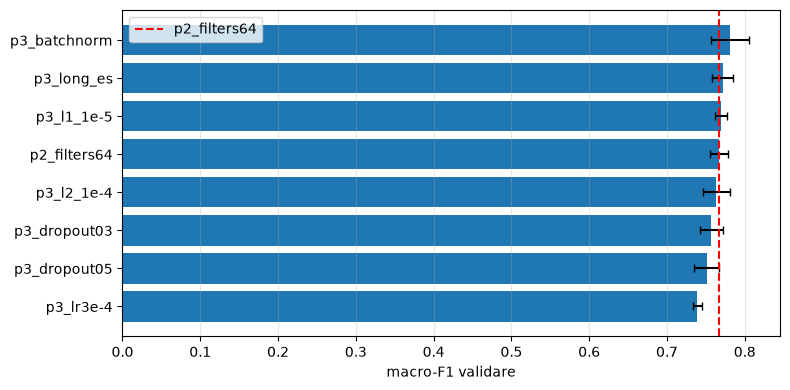

In [ ]:

def load_summary():
    runs = lab4_common.OUT_DIR / "runs"
    names = [d.name for d in sorted(runs.glob("*"))
             if d.is_dir() and all((d / f"fold{k}.json").exists() for k in range(5))]
    df = pd.DataFrame([lab4_common._summary(n) for n in names])
    return df.sort_values("val_f1_mean", ascending=False, ignore_index=True)

summary = load_summary()
p3 = summary[summary["name"].isin(["p2_filters64"] + list(GRID))].copy()
p3["gap_train_val"] = p3["train_f1_mean"] - p3["val_f1_mean"]
cols = ["name", "val_f1_mean", "val_f1_std", "train_f1_mean", "gap_train_val", "best_epoch_mean", "train_minutes_total"]
display(p3[cols].round(3))

plot_df = p3.sort_values("val_f1_mean")
plt.figure(figsize=(8, 4))
plt.barh(plot_df["name"], plot_df["val_f1_mean"], xerr=plot_df["val_f1_std"], capsize=3)
plt.axvline(base["val_f1_mean"], color="red", linestyle="--", label="p2_filters64")
plt.xlabel("macro-F1 validare"); plt.legend(); plt.grid(axis="x", alpha=0.3); plt.tight_layout(); plt.show()

### Interpretare

Diferența dintre F1 pe antrenare și F1 pe validare arată cât overfitting are fiecare model. La modelul de pornire ea este 0.085.

L2, dropout-ul și learning rate-ul mai mic au redus mult această diferență, deci au redus overfitting-ul, dar au scăzut și F1 pe antrenare.
Modelul învață mai încet și nu mai ajunge la aceeași performanță în 30 de epoci, așa că F1 pe validare a scăzut.
Augmentarea imaginilor regularizează deja modelul, deci regularizarea în plus a fost prea mult.

Batch normalization este singura schimbare care a redus overfitting-ul (0.065) și a crescut F1 pe validare (0.781).
Cea mai bună epocă este în medie 18, mai devreme decât la celelalte, deci antrenarea devine mai stabilă și mai rapidă.

Antrenarea mai lungă a crescut puțin F1 pe validare, dar și overfitting-ul (0.101).
Timpii nu se compară cu modelul de pornire, deoarece experimentele Părții 3 au rulat pe un laptop mai lent.

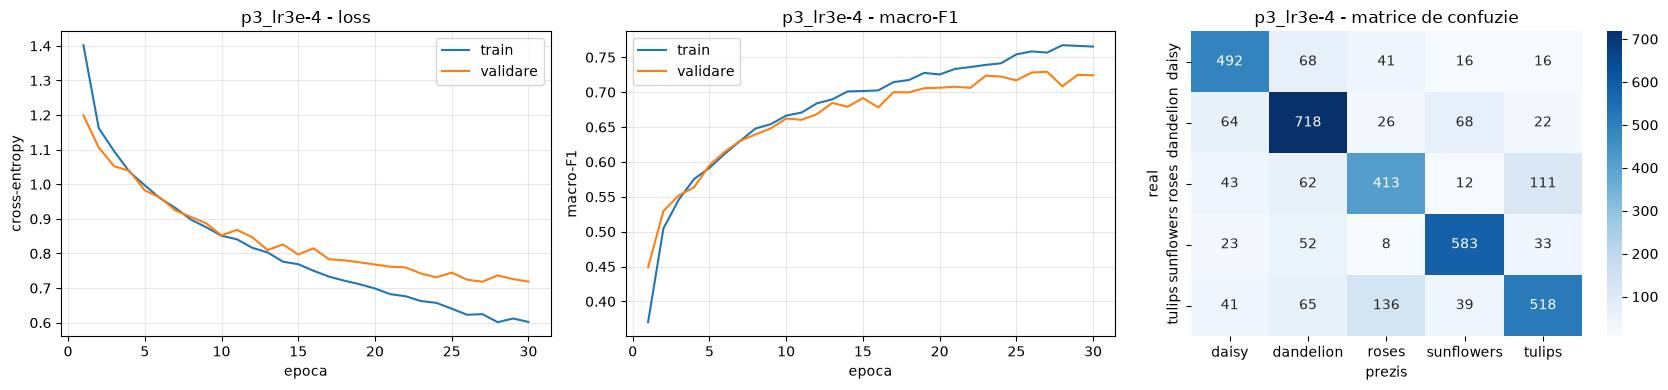

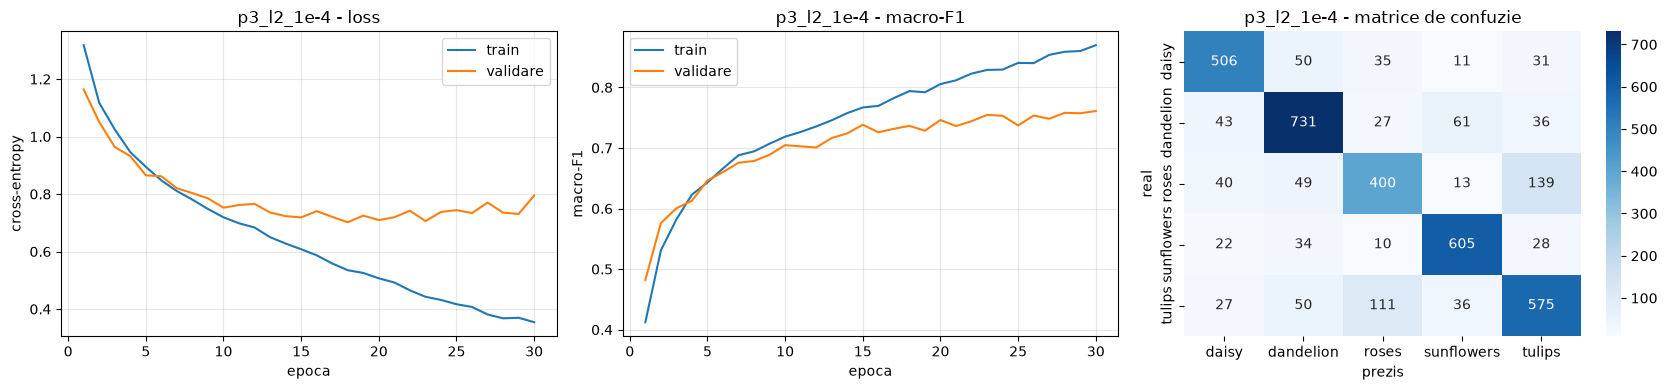

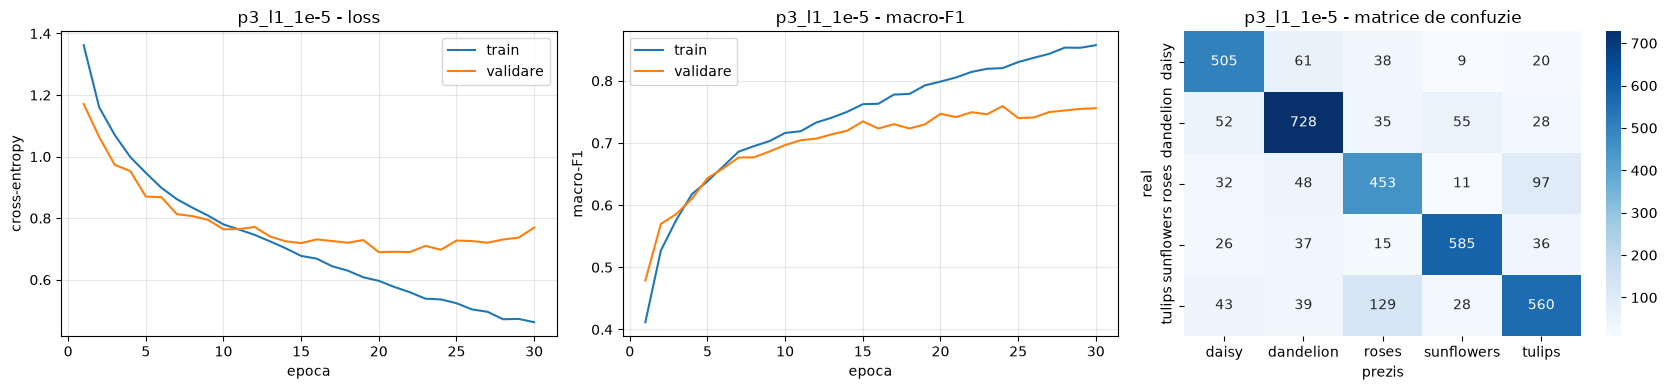

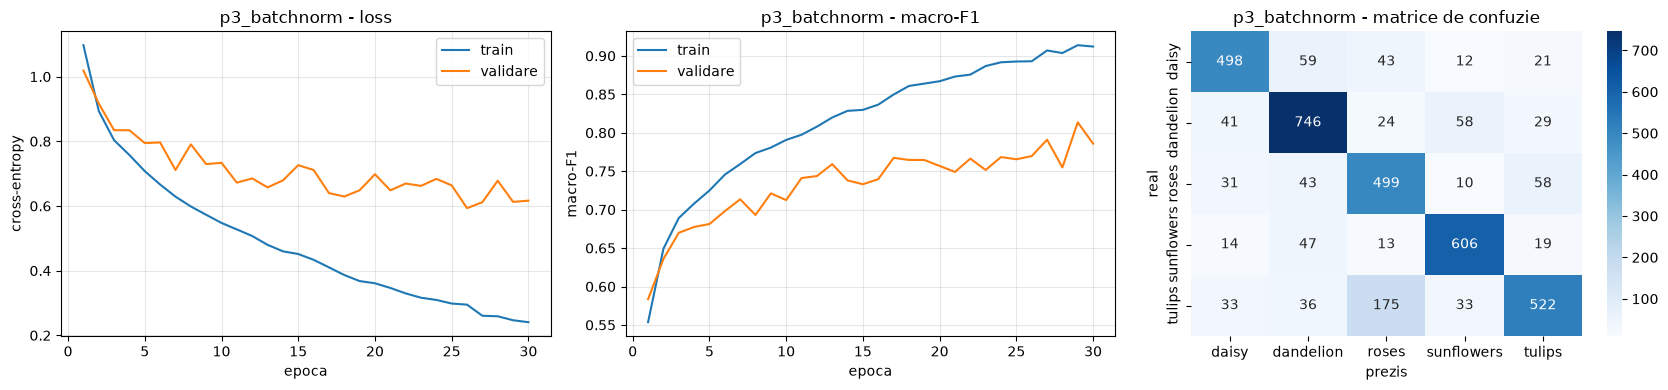

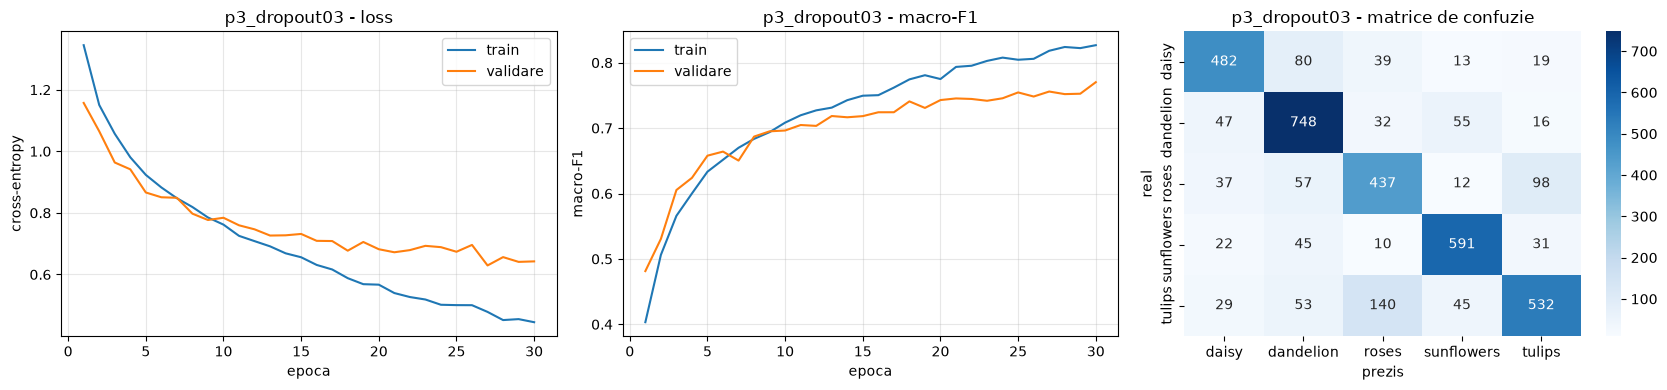

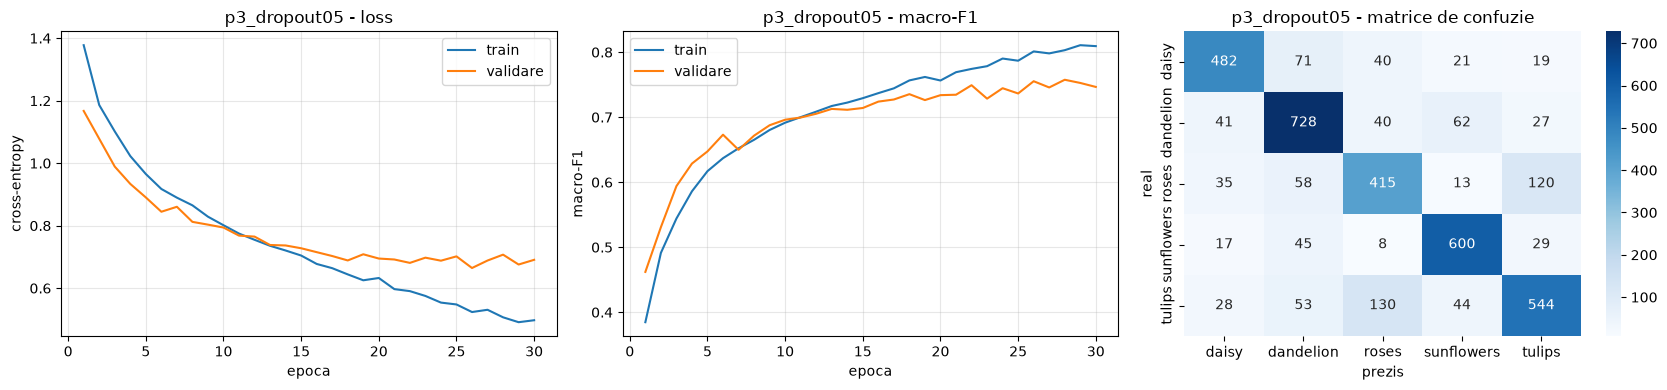

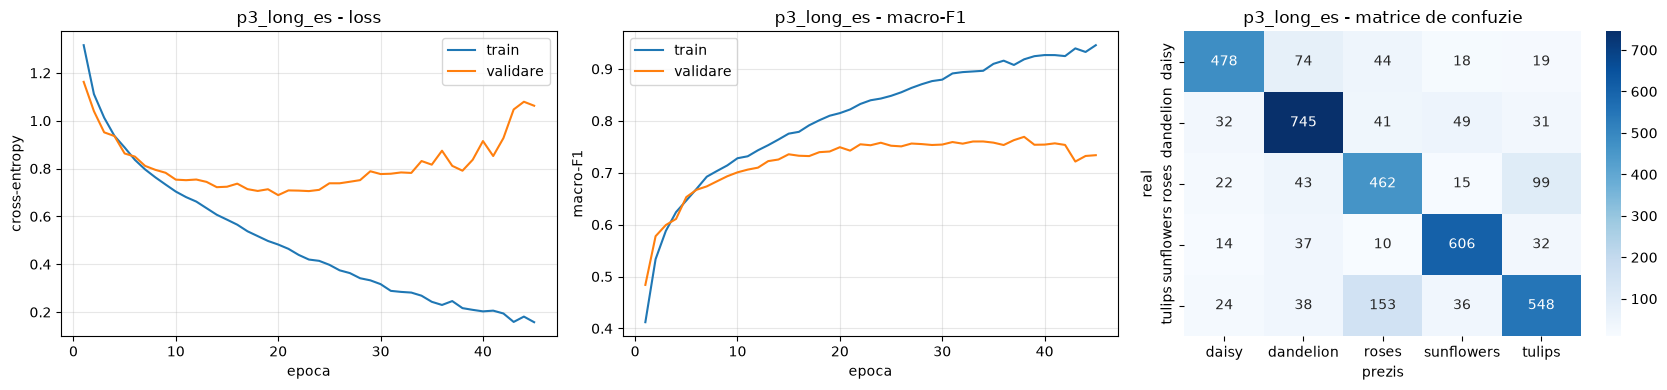

In [6]:
for name in GRID:
    fig, axes = plt.subplots(1, 3, figsize=(17, 4))
    lab4_common.plot_history(name, ax=axes[:2])
    lab4_common.plot_confusion(name, ax=axes[2], normalize=False)
    plt.show()

### Ce arată curbele de antrenare și matricile de confuzie

La learning rate 0.0003 și la dropout, curbele de antrenare și validare rămân apropiate, iar F1 pe validare încă crește la epoca 30.
Overfitting-ul este mic, dar modelul nu a avut suficiente epoci ca să învețe complet, de aceea rezultatul final este mai slab.

La L1 și L2, loss-ul de validare se oprește din scădere în jurul epocii 15–20 și apoi începe să crească, în timp ce loss-ul de antrenare
continuă să scadă. Regularizarea nu a fost suficientă pentru a opri overfitting-ul.

La batch normalization, loss-ul de validare este cel mai mic dintre toate experimentele (în jur de 0.6), iar F1 pe validare ajunge aproape de 0.8.
Curbele de validare sunt însă mai agitate de la o epocă la alta, ceea ce explică și deviația standard mai mare între fold-uri.

Varianta cu 60 de epoci arată cel mai clar overfitting-ul: după epoca 20 loss-ul de validare crește de la 0.7 la peste 1.0,
iar F1 pe validare nu mai crește. Early stopping-ul păstrează greutățile din epoca cea mai bună, deci rezultatul final nu este afectat.

În matricile de confuzie, cea mai mare problemă rămâne confuzia dintre trandafiri și lalele, la toate experimentele.
Batch normalization a îmbunătățit clar recunoașterea trandafirilor (499 corecte, față de aproximativ 400–450 la celelalte),
dar a crescut numărul de lalele clasificate ca trandafiri. Celelalte confuzii frecvente sunt între păpădie și floarea-soarelui
și între margaretă și păpădie, flori cu culori și forme asemănătoare la 64x64 pixeli.

In [7]:
def fold_info(name):
    rows = [json.loads((lab4_common.OUT_DIR / "runs" / name / f"fold{k}.json").read_text()) for k in range(5)]
    return pd.DataFrame(rows)[["fold", "best_epoch", "epochs_run", "val_f1", "train_seconds"]].assign(experiment=name)

es = pd.concat([fold_info("p2_filters64"), fold_info("p3_long_es")])
display(es.round(3))

,fold,best_epoch,epochs_run,val_f1,train_seconds,experiment
0,0,27,30,0.779,76.414,p2_filters64
1,1,24,29,0.780,73.273,p2_filters64
2,2,30,30,0.760,76.329,p2_filters64
3,3,18,23,0.753,58.665,p2_filters64
4,4,28,30,0.762,75.803,p2_filters64
0,0,24,34,0.780,492.187,p3_long_es
1,1,32,42,0.788,588.463,p3_long_es
2,2,35,45,0.764,713.990,p3_long_es
3,3,26,36,0.774,503.184,p3_long_es
4,4,26,36,0.754,471.854,p3_long_es


### Când se oprește antrenarea și ce câștigăm cu early stopping

La modelul de pornire (maximum 30 de epoci, patience 5), antrenarea a ajuns la limita de 30 de epoci în 3 din cele 5 fold-uri,
iar cea mai bună epocă a fost în medie 25.4. Early stopping-ul a intervenit doar în 2 fold-uri, deci limita de epoci
a oprit antrenarea mai des decât early stopping-ul.

Cu maximum 60 de epoci și patience 10, early stopping-ul a oprit antrenarea în toate fold-urile, între epocile 34 și 45,
mult înainte de limita de 60. Cea mai bună epocă a fost în medie 28.6, iar în două fold-uri a fost după epoca 30 (32 și 35),
deci aceste fold-uri aveau nevoie de mai multe epoci decât permitea modelul de pornire.

F1 pe validare a crescut ușor în 4 din 5 fold-uri, iar media a ajuns la 0.772 față de 0.767. Câștigul este mic, pentru că după
aproximativ 30 de epoci modelul începe să facă overfitting, așa cum se vede pe curbele de loss. Early stopping-ul oprește
antrenarea la timp și păstrează greutățile din epoca cea mai bună.

Timpii nu se pot compara direct, deoarece cele două experimente au rulat pe laptopuri diferite.

## Modelul final

Combinăm cele mai bune setări din grid și antrenăm mai mult (60 de epoci, patience 10), cu augmentare.

In [9]:

FINAL_CHANGES = dict(batch_norm=True, l1=1e-5)
print("Setari alese pentru modelul final:", FINAL_CHANGES)

final_cfg = lab4_common.make_config(**{**BASE, **FINAL_CHANGES, "epochs": 60, "patience": 10, "name": "p3_final"})
lab4_common.run_experiment(final_cfg, device=DEVICE, verbose=False)

Setari alese pentru modelul final: {'batch_norm': True, 'l1': 1e-05}
[p3_final] gata: macro-F1 = 0.796 ± 0.023


{'name': 'p3_final',
 'val_f1_mean': 0.796226706313363,
 'val_f1_std': 0.022910989155753198,
 'val_acc_mean': 0.7986376021798365,
 'train_f1_mean': 0.8875072907951577,
 'best_epoch_mean': 27.8,
 'train_minutes_total': 68.98650493621827,
 'infer_ms_per_image': 2.584716994366139,
 'n_params': 601349,
 'model_mb': 2.3058900833129883,
 'device': 'cpu',
 'img_size': 64,
 'conv_layers': '[64, 64, 64]',
 'kernel_size': 3,
 'stride': 1,
 'pooling': 'max',
 'recurrent': None,
 'rnn_hidden': 128,
 'fc_layers': '[128]',
 'activation': 'relu',
 'batch_norm': True,
 'dropout': 0.0,
 'augment': True,
 'optimizer': 'adam',
 'lr': 0.001,
 'weight_decay': 0.0,
 'l1': 1e-05,
 'batch_size': 64,
 'epochs': 60,
 'patience': 10}

### Rezultatul modelului final

Modelul final combină batch normalization și regularizarea L1, cu maximum 60 de epoci și patience 10.
A obținut macro-F1 0.796 ± 0.023, cel mai bun rezultat din toate experimentele echipei:
cu 0.029 mai mult decât modelul de pornire (0.767) și cu 0.015 mai mult decât batch normalization singur (0.781).

Cele două schimbări se completează: batch normalization stabilizează și accelerează antrenarea, iar L1 limitează ușor
creșterea parametrilor, iar antrenarea mai lungă îi lasă modelului timp să profite de ele.
F1 pe antrenare este 0.888, deci modelul încă face overfitting, dar mai puțin decât ar fi făcut fără regularizare cu 60 de epoci.

Modelul are 601 349 de parametri (doar 640 în plus față de modelul de pornire, de la straturile de batch normalization),
ocupă 2.3 MB pe disc și clasifică o imagine în aproximativ 2.6 ms pe CPU.

In [ ]:
print(lab4_common.model_summary(final_cfg))

## Mărimea modelelor pe disc

Mărimea fișierului salvat pentru toate experimentele echipei. Depinde aproape doar de numărul de parametri.

In [ ]:
summary = load_summary()
size = summary.sort_values("model_mb")
plt.figure(figsize=(8, max(4, 0.28 * len(size))))
plt.barh(size["name"], size["model_mb"])
plt.xscale("log"); plt.xlabel("MB pe disc (scara logaritmica)"); plt.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()
display(size[["name", "n_params", "model_mb"]].round(3))

## Imaginile clasificate greșit de majoritatea modelelor

Pentru fiecare imagine numărăm câte modele au greșit-o, din predicțiile de validare ale tuturor experimentelor.

In [ ]:
C = lab4_common.CLASSES
preds = []
for name in summary["name"]:
    f = lab4_common.OUT_DIR / "runs" / name / "predictions.csv"
    if f.exists():
        d = pd.read_csv(f)[["path", "true", "pred"]]
        d["model"] = name
        preds.append(d)
allp = pd.concat(preds)
allp["wrong"] = allp["true"] != allp["pred"]
print("Modele folosite:", allp["model"].nunique())

agg = allp.groupby("path").agg(true=("true", "first"), wrong_frac=("wrong", "mean"),
                               pred=("pred", lambda s: s.mode().iloc[0]))
print("Imagini gresite de peste jumatate din modele:", (agg["wrong_frac"] > 0.5).sum())

top = agg.sort_values("wrong_frac", ascending=False).head(12)
titles = [f"real: {C[t]}\nprezis: {C[p]} ({w:.0%})" for t, p, w in zip(top["true"], top["pred"], top["wrong_frac"])]
lab4_common.show_images(top.index.tolist(), titles, ncols=6, size=2.6)
plt.show()

## Tabelul final

Toate experimentele echipei, cu configurația, macro-F1, timpul de antrenare, numărul de parametri și mărimea pe disc.
Timpii sunt măsurați pe laptopuri diferite, deci se compară doar în cadrul aceleiași părți.

In [ ]:
cols = ["name", "conv_layers", "pooling", "fc_layers", "recurrent", "lr", "weight_decay", "l1",
        "batch_norm", "dropout", "epochs", "val_f1_mean", "val_f1_std", "train_minutes_total",
        "n_params", "model_mb", "device"]
final_table = load_summary()[cols]
display(final_table.round(4))

## CPU vs GPU

Comparația timpilor de antrenare pe CPU și pe GPU, pentru 3–4 experimente diferite, rulată în Google Colab
(același calculator pentru ambele variante).

In [ ]:
cpu_gpu = pd.read_csv(lab4_common.OUT_DIR / "cpu_vs_gpu.csv")
print("CPU:", cpu_gpu["cpu_model"].iloc[0])
print("GPU:", cpu_gpu["gpu_model"].iloc[0])
table = cpu_gpu.pivot(index="experiment", columns="device", values="sec_per_epoch")
table["de_cate_ori_mai_rapid_pe_GPU"] = table["cpu"] / table["cuda"]
display(table.round(2))

Am rulat 4 modele diferite în Google Colab, pe același calculator, o dată pe CPU (Intel Xeon @ 2.00 GHz, 2 nuclee)
și o dată pe GPU (NVIDIA Tesla T4), câte 5 epoci pe un singur fold.

GPU-ul a fost mai rapid la toate modelele, dar câștigul depinde de cât calcul face modelul:
de 6 ori pentru rețeaua fără convoluții, de 34 de ori pentru CNN cu LSTM, de 40 de ori pentru modelul de bază
și de 50 de ori pentru modelul fără pooling, care are cele mai multe calcule.
Convoluțiile se pot face în paralel pe miile de nuclee ale GPU-ului, iar la rețeaua mică timpul este dominat
de operații care nu se accelerează (augmentarea, bucla de antrenare).

Procesorul din Colab are doar 2 nuclee, deci față de un laptop modern diferența ar fi ceva mai mică,
dar concluzia rămâne aceeași: pentru rețele convoluționale, GPU-ul reduce timpul de antrenare de zeci de ori.

## Concluzii